Données de la base GDELT cloud et comparaison à l'inactivité et à la population en QPV

Avant de pouvoir explorer ces données, il faut importer quelques modules, et bien sûr les données, en utilisant le code suivant : 

In [11]:
## Importation des modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import json, s3fs

np.random.seed(123)

## Importation des données
fs = s3fs.S3FileSystem(client_kwargs={"endpoint_url": "https://minio.lab.sspcloud.fr"})
CACHE = "vgounot/diffusion"

with fs.open(f"{CACHE}/gcloud_emeutes_all.json", "r", encoding="utf-8") as f:
    body = json.load(f)

Tout d'abord, il s'agit de nettoyer le jeu de données à notre disposition. En effet, après plusieurs essais et différentes cartes, nous avons rencontré différents types de données qu'il est souhaitable d'éliminer : 
     - Des émeutes dont la localisation n'est pas précisée, et qui se retrouvent toutes au même endroit dans la Creuse
     - Des émeutes qui n'ont pas eu lieu en France (une donnée à Barcelone)
     - Des émeutes en Outre-mer, retirées par souci de simplicité pour réaliser les cartes ensuite
Nous avons donc dû retirer douze lignes à la base de données initiale afin de simplifier la réalisation de la carte, et de ne pas fausser les analyses, notamment lorsque l'on regarde le nombre d'émeutes à l'échelle départementale (qui donnait alors la Creuse deuxième derrière Paris, alors qu'en réalité, il n'y a pas eu d'émeutes en Creuse).
De plus, le format des données a été un défi. En effet, le fichier json comportait des imbrications, rendant une extraction des données en deux temps, et une sélection des données à extraire. En effet, nous avons laissé certaines colonnes avec des données sous la forme de dictionnaires car elles ne nous étaient pas utiles, et nous avons extrait des dictionnaires uniquement les données qui nous intéressaient, à savoir latitude, longitude, localisation et pays, les deux derniers servant au nettoyage.
Le nettoyage se fait avec le code ci-après : 

In [12]:
data = pd.DataFrame(body) #read_json ne fonctionne pas car le json est "imbriqué" donc je crée une dataframe qui garde les dictionnaires de second niveau

data["lat"] = data["geo"].apply(lambda x: x["latitude"])
data["long"] = data["geo"].apply(lambda x: x["longitude"]) 
data["pays"] = data["geo"].apply(lambda x: x["country"])
data["loc"] = data["geo"].apply(lambda x: x["location"])
#On utilise la fonction apply pour appliquer une fonction à chaque élément d'une colonne
#On a maintenant deux colonnes qui nous donnent la localisation exacte des émeutes

## Nettoyage préalable

#On retire les données manquantes si jamais il y en a (et seulement si c'est la latitude ou la longitude qui manque)
data = data.dropna(subset=["lat", "long"])
#On retire aussi les Outre-mer sinon on aura des points partout dans le monde et ce sera illisible
data = data[(data["lat"]>=41.3)&(data["lat"]<=51.2)&(data["long"]>=-5.2)&(data["long"]<=9.7)]

data = data[data["pays"]=="France"] #On a remarqué un point un Espagne que l'on retire
data = data.dropna(subset=["loc"]) #On retire aussi les points non précis qui atterrissent tous au même endroit dans la Creuse

La première étape pour utiliser ces données a été de localiser ces données sur une carte, afin de vérifier leur bonne répartition sur le territoire français, et afin d'avoir une première idée des lieux des émeutes.
Il en ressort que, dans la grande majorité des cas, les émeutes ont lieu dans des grandes villes et notamment dans des préfectures (ou dans des sous-préfectures dans de plus rares cas). On peut aisément l'observer sur la carte ci-dessous : 

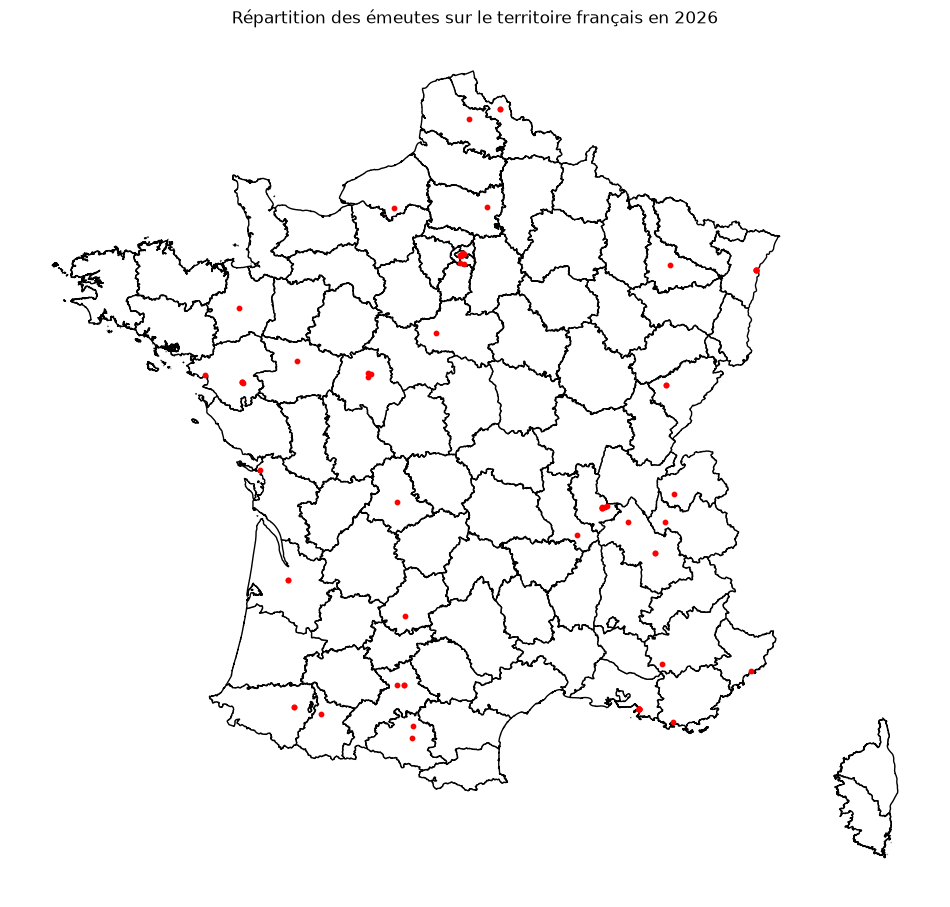

In [13]:
## Importation du fond de carte

url_fond_de_carte = ("https://minio.lab.sspcloud.fr/projet-cartiflette/production/"
       "provider=IGN/dataset_family=ADMINEXPRESS/"
       "source=EXPRESS-COG-CARTO-TERRITOIRE/year=2022/"
       "administrative_level=DEPARTEMENT/crs=4326/FRANCE_ENTIERE=France/"
       "vectorfile_format=geojson/territory=metropole/simplification=50/raw.geojson")

departements = gpd.read_file(url_fond_de_carte)
departements = departements[~departements["INSEE_DEP"].str.startswith("97")] 
#On retire les Outre-mer sinon la carte ne va ressembler à rien
departements = departements.to_crs(2154) #On passe en projection Lambert 93

## Création des points

points = gpd.GeoDataFrame(data, geometry=gpd.points_from_xy(data["long"], data["lat"]), crs=4326)
points = points.to_crs(2154) #On passe en projection Lambert 93

## Projection des points sur la carte

#Ici, je ne vois pas comment faire la jointure. On va donc superposer le fond de carte et les points
fig, ax = plt.subplots(figsize=(12,12))
departements.plot(ax=ax, color="white", edgecolor="black")
ax.set_axis_off()
ax.set_title("Répartition des émeutes sur le territoire français en 2026")
points.plot(ax=ax, color="red", markersize=10, legend=True, legend_kwds={"label": "Emeutes"})
plt.show()


Pour cette carte, la projection choisie est la projection Lambert 93. En effet, c'est celle qui était préconisée par le cours pour représenter la France car c'est la projection généralement utilisée pour ce genre d'usage. 

On peut ensuite agréger ces données au niveau du département en comptant le nombre d'émeutes par département depuis mars 2026. On obtient alors une nouvelle carte : 

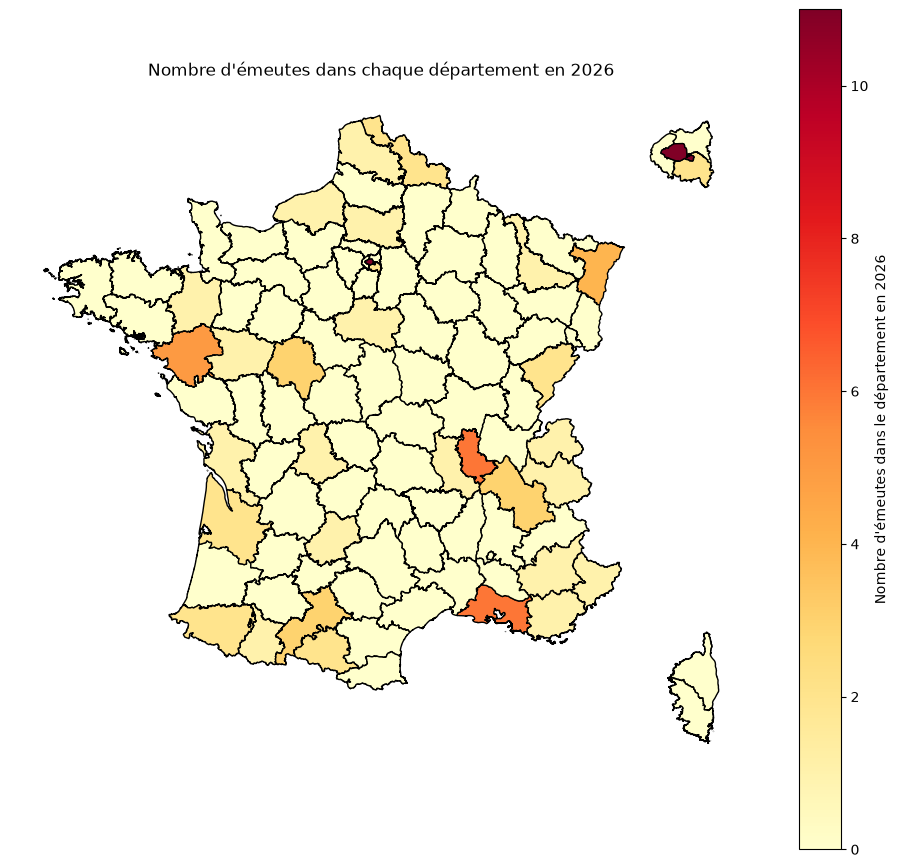

In [14]:
## Agrégation des émeutes par département

emeutes_département = gpd.sjoin(points, departements[["INSEE_DEP", "geometry"]], how="left", predicate="within")
# Cela permet d'attribuer un département à chaque de la carte
emeutes_département = emeutes_département.dropna(subset=["INSEE_DEP"])
# Il y a un point en dehors de la France sur la carte précédente, donc je préfère retirer la donnée pour la suite

émeutes_agrégé = emeutes_département["INSEE_DEP"].value_counts()
#On compte le nombre de fois où chaque département apparaît pour avoir le nombre d'événements récents par départements

carte2 = departements.merge(émeutes_agrégé, on="INSEE_DEP", how="left")
carte2["count"] = carte2["count"].fillna(0)
#Lorsque la valeur de count n'a pas été trouvée, c'est qu'il n'y a pas eu d'émeutes

petite_couronne = carte2[carte2["INSEE_DEP"].isin(["75", "92", "93", "94"])]

variable = "count"

vmin = carte2["count"].min()
vmax = carte2["count"].max()

fig = plt.figure(figsize=(16,10))

ax1 = fig.add_axes([0.03, 0.08, 0.58, 0.84])
ax2 = fig.add_axes([0.35, 0.65, 0.20, 0.25])

graphe2 = carte2.plot(column=variable, ax=ax1, cmap="YlOrRd", vmin=vmin, vmax=vmax, edgecolor="black", legend=True, legend_kwds={"label" : "Nombre d'émeutes dans le département en 2026"})
petite_couronne.plot(column=variable, ax=ax2, cmap="YlOrRd", vmin=vmin, vmax=vmax, edgecolor="black")
graphe2.set_axis_off()
graphe2.set_title("Nombre d'émeutes dans chaque département en 2026")
xmin, ymin, xmax, ymax = petite_couronne.total_bounds
ax2.set_xlim(xmin-50000, xmax+50000)
ax2.set_ylim(ymin-50000, ymax+50000)
ax2.set_axis_off()
plt.show()


Grâce à cette carte, on peut confirmer notre intuition de l'autre carte : c'est bien là où se trouvent les grandes villes qu'il y a le plus d'émeutes. En effet, les départements les plus foncés sur cette carte sont Paris (75), les Bouches-du-Rhône (13 - Marseille), le Rhône (69 - Lyon), mais aussi la Loire-Atlantique (44 - Nantes) et le Bas-Rhin (67 - Strasbourg). A l'inverse, les départements ruraux sont en général plus clairs, ce qui signifie qu'il y a moins d'émeutes dans ces départements, comme par exemple la Haute-Loire (43) ou le Cantal (15) qui n'ont pas connu d'émeutes depuis mars 2026. 
Ayant des données à l'échelle des départements sur l'inactivité chez les jeunes et la population résident en QPV, nous allons maintenant pouvoir comparer cette répartition géographique des émeutes aux données. 